# Dog breed segments: PCA and clustering

**Goal:** group dog breeds by how they move through the shelter, then find which breed segments are adopted fastest and slowest (README: segmentation).

**Approach:**
1. **Breed profiles:** for each primary breed with ≥ 100 stays in the **training years (before 2022)**, compute a profile of 15 shelter statistics: outcome rates, stay length, intake mix, age, sterilization, and so on.
2. **PCA** on the standardized profiles: which combinations of statistics separate breeds the most?
3. **k-means** on the leading principal components → breed segments.

**Caveats:**
- **Breed is the shelter-assigned label,** judged visually, and known to be unreliable (especially for "Pit Bull"). Mixed breeds are counted under their first-listed breed.
- **Breeds are summarized, not individual animals,** and all differences are associations. A segment's outcomes reflect who comes in under that label (age, intake type, owner status), not something intrinsic to the breed.
- **Only training years are used,** so segment labels could later be used as a model feature without leaking val/test information.
- **Cats are excluded:** only 9 cat breeds have ≥ 100 stays, and "Domestic Shorthair" alone is most of them, too few for PCA.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

sys.path.append(str(Path.cwd().parent))
import utils

RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
MIN_N = 100
sns.set_theme(style="whitegrid")

ep = utils.load_austin_episodes()
dogs = ep[(ep["animal_type"] == "Dog") & (ep["intake_dt"] < utils.VAL_START)].copy()
done = (dogs["has_outcome"] == 1) & (dogs["los_suspect"] == 0)
dogs["los_valid"] = dogs["los_days"].where(done)
dogs["long_stay"] = (dogs["los_days"] >= 30).where(done)
for c in utils.OUTCOME_CLASSES:
    dogs[f"out_{c}"] = (dogs["outcome_group"] == c).where(dogs["outcome_group"].isin(utils.OUTCOME_CLASSES))
print(f"{len(dogs):,} dog stays before 2022, {dogs['breed_primary'].nunique()} primary breeds")

75,969 dog stays before 2022, 206 primary breeds


## 1. Breed profiles

In [2]:
g = dogs.groupby("breed_primary")
profiles = pd.DataFrame({
    "n_stays": g.size(),
    # outcomes (share of the 4 modeled outcomes)
    "adoption_rate": g["out_Adoption"].mean(),
    "transfer_rate": g["out_Transfer"].mean(),
    "return_to_owner_rate": g["out_Return to Owner"].mean(),
    "euthanasia_rate": g["out_Euthanasia"].mean(),
    # stay length
    "median_stay_days": g["los_valid"].median(),
    "long_stay_share": g["long_stay"].mean(),
    # who comes in
    "stray_share": g["intake_type"].apply(lambda s: (s == "Stray").mean()),
    "owner_surrender_share": g["intake_type"].apply(lambda s: (s == "Owner Surrender").mean()),
    "not_normal_condition_share": g["intake_condition"].apply(lambda s: (s != "Normal").mean()),
    "median_age_years": g["age_days"].median() / 365.25,
    "puppy_share": g["age_days"].apply(lambda s: (s < 182).mean()),
    "fixed_at_intake_share": g["fixed_status"].apply(lambda s: (s == "Fixed").mean()),
    "mix_share": g["is_mix"].mean(),
    "named_share": g["has_name"].mean(),
    "repeat_visit_share": g["is_return"].mean(),
})
profiles = profiles[profiles["n_stays"] >= MIN_N].sort_values("n_stays", ascending=False)
FEATS = profiles.columns.drop("n_stays").tolist()
print(f"{len(profiles)} breeds with >= {MIN_N} stays, covering "
      f"{profiles['n_stays'].sum() / len(dogs):.1%} of dog stays")
profiles.head(12).round(2)

79 breeds with >= 100 stays, covering 95.5% of dog stays


,n_stays,adoption_rate,transfer_rate,return_to_owner_rate,euthanasia_rate,median_stay_days,long_stay_share,stray_share,owner_surrender_share,not_normal_condition_share,median_age_years,puppy_share,fixed_at_intake_share,mix_share,named_share,repeat_visit_share
breed_primary,,,,,,,,,,,,,,,,
Pit Bull,11317,0.418497,0.197065,0.334549,0.049889,8.89,0.249463,0.66,0.20,0.12,2.0,0.15,0.36,0.84,0.64,0.22
Labrador Retriever,10712,0.531018,0.213046,0.236696,0.01924,6.05,0.155051,0.70,0.22,0.09,1.0,0.34,0.37,0.88,0.58,0.16
Chihuahua Shorthair,8734,0.489565,0.249971,0.237058,0.023406,4.89,0.076976,0.69,0.23,0.12,2.0,0.19,0.30,0.85,0.59,0.10
German Shepherd,5229,0.537279,0.173136,0.270369,0.019216,6.02,0.122003,0.69,0.22,0.10,1.0,0.26,0.34,0.79,0.64,0.17
Australian Cattle Dog,2432,0.585638,0.186546,0.209245,0.018572,7.01,0.165908,0.68,0.24,0.08,1.0,0.28,0.36,0.85,0.58,0.15
Dachshund,1837,0.514754,0.253552,0.213115,0.018579,4.77,0.057829,0.70,0.22,0.10,2.0,0.24,0.33,0.87,0.60,0.09
Boxer,1614,0.48351,0.203485,0.281892,0.031114,6.83,0.16823,0.68,0.22,0.09,2.0,0.18,0.40,0.86,0.65,0.20
Border Collie,1514,0.558278,0.182119,0.243046,0.016556,5.94,0.121192,0.66,0.25,0.08,1.0,0.27,0.40,0.90,0.64,0.15
Siberian Husky,1435,0.486354,0.114766,0.377187,0.021693,4.34,0.078158,0.73,0.20,0.08,2.0,0.12,0.35,0.64,0.72,0.20


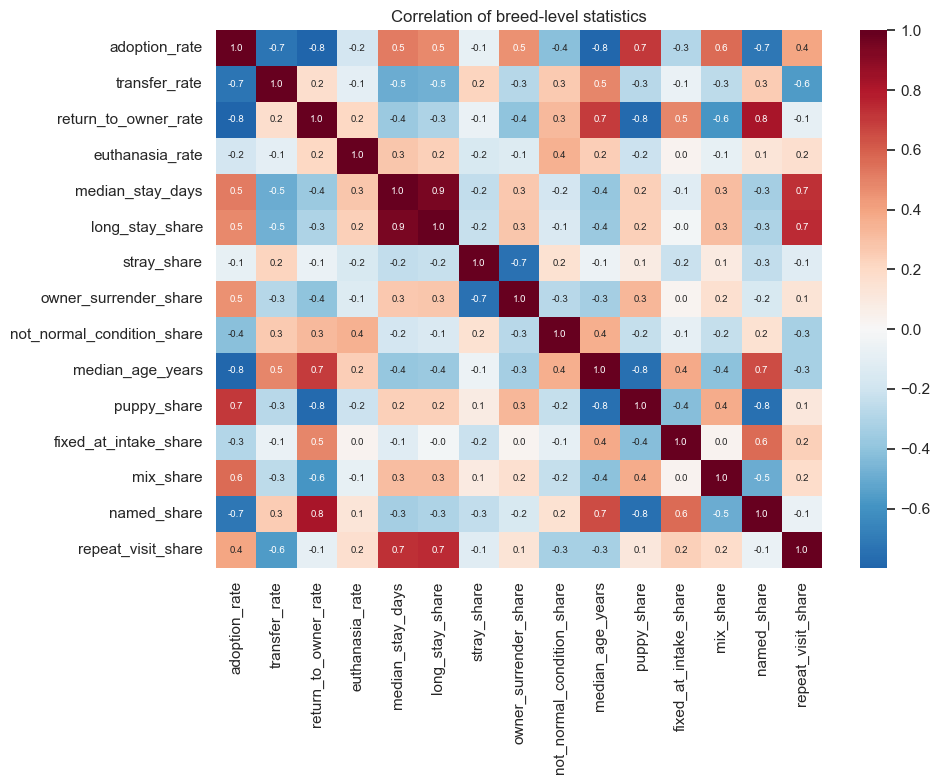

In [3]:
# Correlation between profile statistics: strongly correlated groups will load on the same PC
plt.figure(figsize=(10, 8))
sns.heatmap(profiles[FEATS].corr(), cmap="RdBu_r", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Correlation of breed-level statistics")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "breed_feature_corr.png", dpi=150, bbox_inches="tight"); plt.show()

## 2. PCA

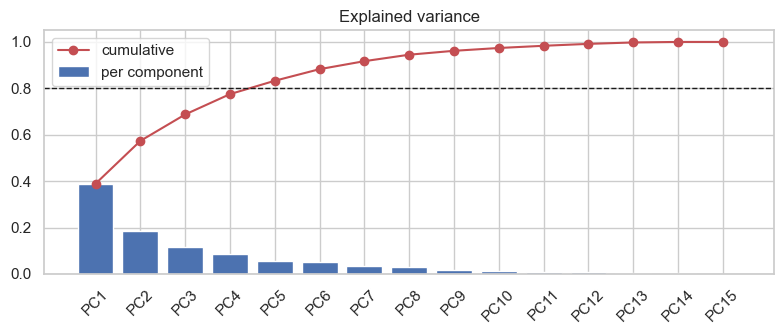

5 components explain 83% of the variance


PC1    0.389
PC2    0.573
PC3    0.687
PC4    0.775
PC5    0.833
PC6    0.883
dtype: float64

In [4]:
Z = StandardScaler().fit_transform(profiles[FEATS])
pca = PCA(random_state=utils.SEED).fit(Z)
evr = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i+1}" for i in range(len(FEATS))])

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(evr.index, evr.values, color="C0", label="per component")
ax.plot(evr.index, evr.cumsum().values, "o-", color="C3", label="cumulative")
ax.axhline(0.8, color="k", ls="--", lw=1)
ax.set_title("Explained variance"); ax.legend(); plt.xticks(rotation=45)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "breed_pca_scree.png", dpi=150, bbox_inches="tight"); plt.show()
N_PC = int(np.argmax(evr.cumsum().values >= 0.8) + 1)
print(f"{N_PC} components explain {evr.cumsum().iloc[N_PC-1]:.0%} of the variance")
evr.cumsum().round(3).head(6)

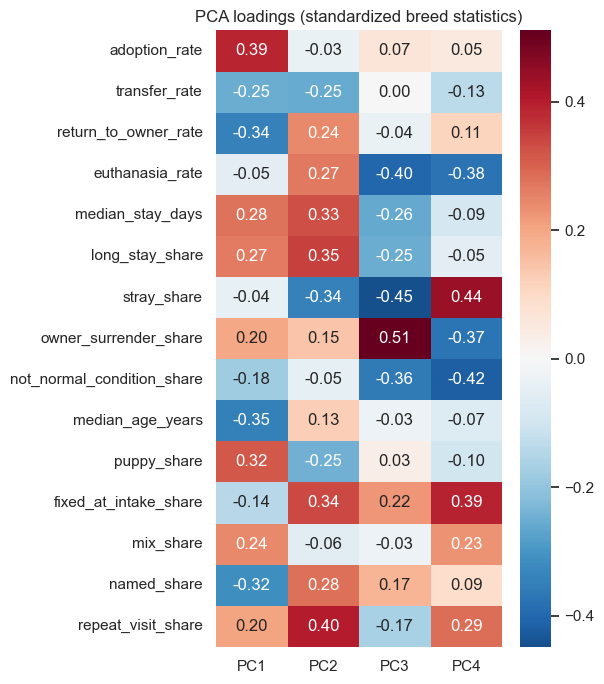

In [5]:
loadings = pd.DataFrame(pca.components_[:4].T, index=FEATS, columns=["PC1", "PC2", "PC3", "PC4"])
plt.figure(figsize=(6, 7))
sns.heatmap(loadings, cmap="RdBu_r", center=0, annot=True, fmt=".2f")
plt.title("PCA loadings (standardized breed statistics)")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "breed_pca_loadings.png", dpi=150, bbox_inches="tight"); plt.show()

In [6]:
scores = pd.DataFrame(pca.transform(Z)[:, :N_PC], index=profiles.index,
                      columns=[f"PC{i+1}" for i in range(N_PC)])
# Biggest movers on each of the first two PCs
for pc in ["PC1", "PC2"]:
    s = scores[pc].sort_values()
    print(f"{pc}  low: {', '.join(s.index[:6])}\n     high: {', '.join(s.index[-6:][::-1])}\n")

PC1  low: Pomeranian, Shih Tzu, Lhasa Apso, Boston Terrier, Pekingese, Cocker Spaniel
     high: Plott Hound, Black Mouth Cur, Pointer, Blue Lacy, Anatol Shepherd, Black-Tan Hound

PC2  low: Border Terrier, Norfolk Terrier, Dachshund Wirehair, Cairn Terrier, Great Pyrenees, Plott Hound
     high: American Bulldog, Staffordshire, Akita, Pit Bull, American Staffordshire Terrier, American Pit Bull Terrier



## 3. Clustering breeds into segments

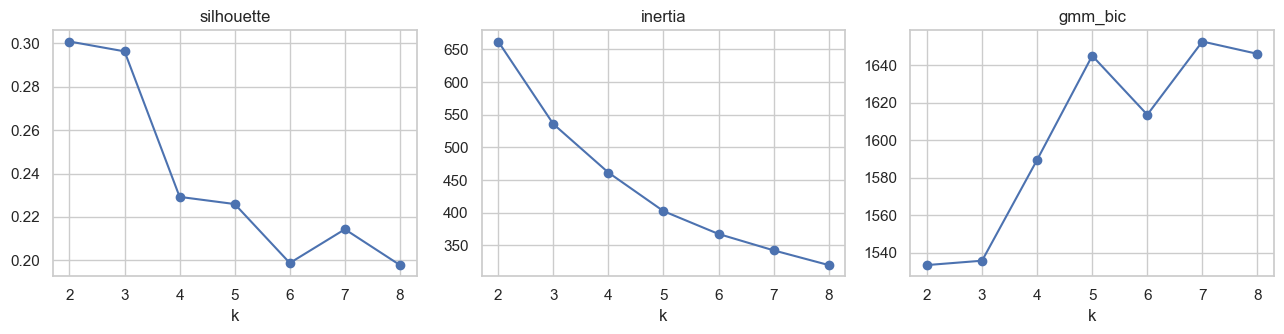

,silhouette,inertia,gmm_bic
k,,,
2,0.301,662.091,1533.306
3,0.296,535.876,1535.636
4,0.229,461.583,1589.447
5,0.226,402.568,1644.961
6,0.199,367.617,1613.488
7,0.214,342.535,1652.546
8,0.198,320.029,1645.959


In [7]:
X = scores.values
rows = []
for k in range(2, 9):
    km = KMeans(k, n_init=20, random_state=utils.SEED).fit(X)
    gm = GaussianMixture(k, n_init=5, random_state=utils.SEED).fit(X)
    rows.append({"k": k, "silhouette": silhouette_score(X, km.labels_), "inertia": km.inertia_, "gmm_bic": gm.bic(X)})
sel = pd.DataFrame(rows).set_index("k")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, c in zip(axes, sel.columns):
    sel[c].plot(marker="o", ax=ax, title=c)
plt.tight_layout(); plt.show()
sel.round(3)

In [8]:
# Pick k by silhouette among k = 3..6 (2 segments is too coarse to be useful for staff)
K = int(sel.loc[3:6, "silhouette"].idxmax())
km = KMeans(K, n_init=20, random_state=utils.SEED).fit(X)
profiles["segment"] = km.labels_
# Order segments by adoption rate so segment 0 = most adopted
order = profiles.groupby("segment")["adoption_rate"].mean().sort_values(ascending=False).index
profiles["segment"] = profiles["segment"].map({old: new for new, old in enumerate(order)})
scores["segment"] = profiles["segment"]
print(f"k = {K}")

k = 3


In [9]:
# Segment profiles, weighted by number of stays so big breeds count more
def wmean(df):
    w = df["n_stays"]
    return pd.Series({c: np.average(df[c], weights=w) for c in FEATS})
seg = profiles.groupby("segment")[["n_stays"] + FEATS].apply(wmean)
seg.insert(0, "n_breeds", profiles.groupby("segment").size())
seg.insert(1, "n_stays", profiles.groupby("segment")["n_stays"].sum())
seg.round(2).T

segment,0,1,2
n_breeds,44.00,12.00,23.00
n_stays,45583.00,17187.00,9791.00
adoption_rate,0.53,0.43,0.35
transfer_rate,0.22,0.19,0.27
return_to_owner_rate,0.23,0.33,0.36
euthanasia_rate,0.02,0.05,0.02
median_stay_days,5.65,8.46,3.93
long_stay_share,0.12,0.23,0.04
stray_share,0.69,0.66,0.72
owner_surrender_share,0.23,0.21,0.18


In [10]:
for s, grp in profiles.groupby("segment"):
    print(f"Segment {s} ({len(grp)} breeds, {grp['n_stays'].sum():,} stays): "
          + ", ".join(grp.sort_values("n_stays", ascending=False).index[:12]))

Segment 0 (44 breeds, 45,583 stays): Labrador Retriever, Chihuahua Shorthair, German Shepherd, Australian Cattle Dog, Dachshund, Border Collie, Great Pyrenees, Beagle, Australian Shepherd, Catahoula, Rat Terrier, Jack Russell Terrier
Segment 1 (12 breeds, 17,187 stays): Pit Bull, Boxer, Staffordshire, Rottweiler, American Bulldog, American Pit Bull Terrier, American Staffordshire Terrier, Chow Chow, Chinese Sharpei, Bull Terrier, Rhod Ridgeback, Akita
Segment 2 (23 breeds, 9,791 stays): Siberian Husky, Miniature Poodle, Yorkshire Terrier, Miniature Schnauzer, Shih Tzu, Maltese, Golden Retriever, Pug, Doberman Pinsch, Basset Hound, Cocker Spaniel, Alaskan Husky


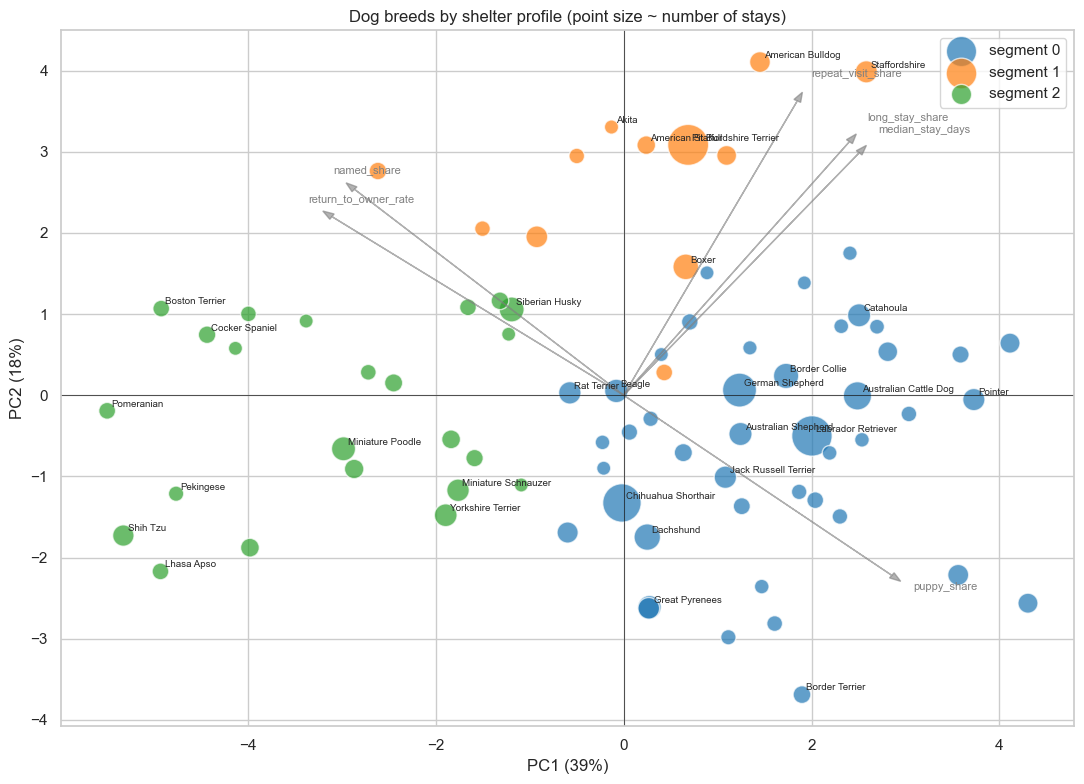

In [11]:
fig, ax = plt.subplots(figsize=(11, 8))
pal = sns.color_palette("tab10", K)
for s in range(K):
    d = scores[scores["segment"] == s]
    ax.scatter(d["PC1"], d["PC2"], s=20 + 8 * np.sqrt(profiles.loc[d.index, "n_stays"]),
               color=pal[s], alpha=.7, label=f"segment {s}", edgecolor="white")
label = set(profiles.index[:20]) | set(scores["PC1"].abs().nlargest(6).index) | set(scores["PC2"].abs().nlargest(6).index)
for b in label:
    ax.annotate(b, (scores.loc[b, "PC1"], scores.loc[b, "PC2"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
# loading arrows for the strongest variables
L2 = loadings[["PC1", "PC2"]]
scale = np.abs(scores[["PC1", "PC2"]]).max().min() * 2.2  # stretch arrows for readability (direction is what matters)
for f in L2.pow(2).sum(axis=1).nlargest(6).index:
    ax.arrow(0, 0, L2.loc[f, "PC1"] * scale, L2.loc[f, "PC2"] * scale, color="grey", alpha=.6, head_width=.08)
    ax.text(L2.loc[f, "PC1"] * scale * 1.08, L2.loc[f, "PC2"] * scale * 1.08, f, color="grey", fontsize=8)
ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5)
ax.set_xlabel(f"PC1 ({evr['PC1']:.0%})"); ax.set_ylabel(f"PC2 ({evr['PC2']:.0%})")
ax.set_title("Dog breeds by shelter profile (point size ~ number of stays)")
ax.legend(loc="best")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "breed_pca_biplot.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Most and least adopted segments

In [12]:
rank = seg[["n_breeds", "n_stays", "adoption_rate", "median_stay_days", "long_stay_share",
            "return_to_owner_rate", "euthanasia_rate"]].sort_values("adoption_rate", ascending=False)
rank.style.format({"n_breeds": "{:.0f}", "n_stays": "{:,.0f}", "median_stay_days": "{:.1f}"}, precision=3) \
    .background_gradient(cmap="Greens", subset=["adoption_rate"]) \
    .background_gradient(cmap="Reds", subset=["long_stay_share", "euthanasia_rate"])

,n_breeds,n_stays,adoption_rate,median_stay_days,long_stay_share,return_to_owner_rate,euthanasia_rate
segment,,,,,,,
0,44,"45,583",0.531,5.7,0.117,0.234,0.018
1,12,"17,187",0.434,8.5,0.234,0.329,0.045
2,23,"9,791",0.345,3.9,0.044,0.363,0.018


In [13]:
out = profiles.join(scores.drop(columns="segment"))
out.to_csv(RESULTS_DIR / "dog_breed_segments.csv")
print("saved", RESULTS_DIR / "dog_breed_segments.csv", out.shape)

saved results/dog_breed_segments.csv (79, 22)


## Takeaways

**Two main axes explain 57% of the variation between breeds** (5 PCs reach 83%):
- **PC1 (39%), "young dogs adopted out" vs. "adult owned dogs reclaimed":**
  - High: adoption rate, puppy share, mixed-breed share, longer stays.
  - Low: return to owner, older age, owner-given names, transfers.
  - Cattle dogs, hounds and pointers sit high; Shih Tzu, Pomeranian, Lhasa Apso and Pekingese sit low.
- **PC2 (18%), "long stays and repeat visits":**
  - High: median stay, 30+ day share, repeat visits, already sterilized at intake, euthanasia, return to owner.
  - Low: strays and puppies.
  - Bully breeds sit at the top: American Bulldog, Staffordshire, Pit Bull, Akita.

**Three segments.** k-means on 5 PCs, k = 3 chosen by silhouette among 3–6. Statistics below are weighted by stays.

| Segment | Example breeds | Breeds / stays | Adoption | Return to owner | Median stay | 30+ days | Euthanasia |
|---|---|---|---|---|---|---|---|
| **0: Common mixes, herding & working dogs** | Labrador, Chihuahua, German Shepherd, Australian Cattle Dog, Dachshund, Border Collie | 44 / 45.6k | **53%** | 23% | 5.7 d | 12% | 2% |
| **1: Bully & large guardian breeds** | Pit Bull, Boxer, Staffordshire, Rottweiler, American Bulldog, Chow Chow, Akita | 12 / 17.2k | 43% | 33% | **8.5 d** | **23%** | **5%** |
| **2: Small companion breeds & huskies** | Siberian Husky, Miniature Poodle, Yorkshire Terrier, Shih Tzu, Maltese, Pug, Golden Retriever | 23 / 9.8k | 35% | **36%** | **3.9 d** | 4% | 2% |

- **The real "needs attention" segment is the bully / large-guardian group.** It has the longest stays (nearly 1 in 4 stays 30+ days), the highest euthanasia rate and the most repeat visits. A shelter could target it with adoption promotions or foster programs.
- **"Least adopted" does not mean "worst off."** Segment 2 has the lowest adoption rate only because owners reclaim these dogs. They have the shortest stays of any segment, and these dogs are older and more often have an owner-given name.
- **The segments are a gradient, not sharply separated** (silhouette ≈ 0.30). Treat them as useful summaries, not natural categories. Many breeds sit near the boundaries.
- **Caveats:**
  - Shelter-assigned breed labels are unreliable, especially "Pit Bull".
  - Mixed breeds are counted under their first-listed breed.
  - Differences reflect *who arrives* under each label (age, owner status, intake route) as much as the breed itself. These are associations, not breed effects.
- **Possible next steps:**
  - add the segment as a model feature (safe, since it was built from training years only);
  - repeat the analysis on 2022+ data to see whether the segments are stable over time.